In [ ]:
# ==========================================
# CREDIT RISK PREDICTION SYSTEM
# ==========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
from google.colab import files
import zipfile
import os

uploaded = files.upload()

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, "r") as zip_ref:
    zip_ref.extractall("credit_risk_data")

print("Files extracted:")
print(os.listdir("credit_risk_data"))

Saving archive.zip to archive.zip
Files extracted:
['credit_risk_dataset.csv']


In [ ]:
df = pd.read_csv("credit_risk_data/credit_risk_dataset.csv")

print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df.head()

Dataset loaded successfully!
Rows: 32581
Columns: 12


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [ ]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (32581, 12)

Column Names:
['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_status', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status       

In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
person_age,32581.0,NaN,NaN,NaN,27.7346,6.348078,20.0,23.0,26.0,30.0,144.0
person_income,32581.0,NaN,NaN,NaN,66074.84847,61983.119168,4000.0,38500.0,55000.0,79200.0,6000000.0
person_home_ownership,32581,4,RENT,16446,NaN,NaN,NaN,NaN,NaN,NaN,NaN
person_emp_length,31686.0,NaN,NaN,NaN,4.789686,4.14263,0.0,2.0,4.0,7.0,123.0
loan_intent,32581,6,EDUCATION,6453,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_grade,32581,7,A,10777,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan_amnt,32581.0,NaN,NaN,NaN,9589.371106,6322.086646,500.0,5000.0,8000.0,12200.0,35000.0
loan_int_rate,29465.0,NaN,NaN,NaN,11.011695,3.240459,5.42,7.9,10.99,13.47,23.22
loan_status,32581.0,NaN,NaN,NaN,0.218164,0.413006,0.0,0.0,0.0,0.0,1.0
loan_percent_income,32581.0,NaN,NaN,NaN,0.170203,0.106782,0.0,0.09,0.15,0.23,0.83


In [ ]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 165


In [ ]:
print(df["loan_status"].value_counts())

print("\nPercentage:")
print(df["loan_status"].value_counts(normalize=True) * 100)

loan_status
0    25473
1     7108
Name: count, dtype: int64

Percentage:
loan_status
0    78.183604
1    21.816396
Name: proportion, dtype: float64


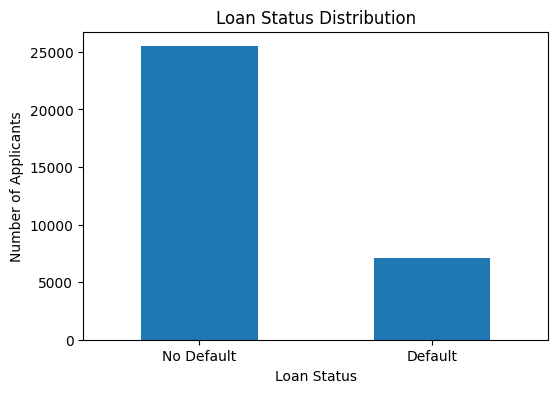

In [ ]:
plt.figure(figsize=(6,4))

df["loan_status"].value_counts().plot(kind="bar")

plt.title("Loan Status Distribution")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applicants")
plt.xticks([0, 1], ["No Default", "Default"], rotation=0)

plt.show()

In [ ]:
X = df.drop("loan_status", axis=1)
y = df["loan_status"]

print("Input features:", X.shape)
print("Target:", y.shape)

Input features: (32581, 11)
Target: (32581,)


In [ ]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical Features:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [ ]:
numeric_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

categorical_pipeline = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numerical_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

print("Preprocessing pipeline created!")

Preprocessing pipeline created!


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (26064, 11)
Testing data: (6517, 11)


In [ ]:
logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(
            max_iter=1000,
            class_weight="balanced"
        ))
    ]
)

logistic_model.fit(X_train, y_train)

y_pred_lr = logistic_model.predict(X_test)
y_prob_lr = logistic_model.predict_proba(X_test)[:, 1]

print("Logistic Regression trained!")

Logistic Regression trained!


In [ ]:
decision_tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(
            max_depth=10,
            random_state=42,
            class_weight="balanced"
        ))
    ]
)

decision_tree_model.fit(X_train, y_train)

y_pred_dt = decision_tree_model.predict(X_test)
y_prob_dt = decision_tree_model.predict_proba(X_test)[:, 1]

print("Decision Tree trained!")

Decision Tree trained!


In [ ]:
random_forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            max_depth=15,
            random_state=42,
            class_weight="balanced",
            n_jobs=-1
        ))
    ]
)

random_forest_model.fit(X_train, y_train)

y_pred_rf = random_forest_model.predict(X_test)
y_prob_rf = random_forest_model.predict_proba(X_test)[:, 1]

print("Random Forest trained successfully!")

Random Forest trained successfully!


In [ ]:
!pip install -q xgboost

In [ ]:
from xgboost import XGBClassifier

xgb_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", XGBClassifier(
            n_estimators=200,
            max_depth=6,
            learning_rate=0.05,
            subsample=0.8,
            colsample_bytree=0.8,
            eval_metric="logloss",
            random_state=42
        ))
    ]
)

xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_prob_xgb = xgb_model.predict_proba(X_test)[:, 1]

print("XGBoost trained successfully!")

XGBoost trained successfully!


In [ ]:
models = {
    "Logistic Regression": (y_pred_lr, y_prob_lr),
    "Decision Tree": (y_pred_dt, y_prob_dt),
    "Random Forest": (y_pred_rf, y_prob_rf),
    "XGBoost": (y_pred_xgb, y_prob_xgb)
}

results = []

for name, (pred, prob) in models.items():

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1 Score": f1_score(y_test, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, prob)
    })

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="ROC-AUC",
    ascending=False
)

results_df

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
3,XGBoost,0.933712,0.975048,0.714487,0.824675,0.947948
2,Random Forest,0.931410,0.960340,0.715190,0.819831,0.931038
1,Decision Tree,0.899647,0.783186,0.746835,0.764579,0.907670
0,Logistic Regression,0.813565,0.551467,0.779887,0.646082,0.871179


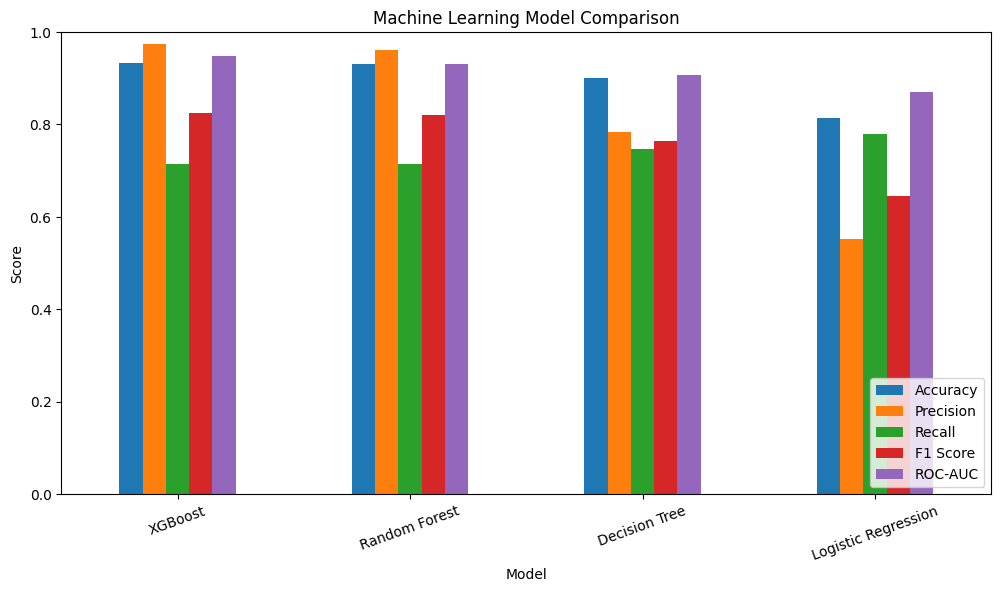

In [ ]:
results_plot = results_df.set_index("Model")

results_plot.plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)

plt.xticks(rotation=20)
plt.legend(loc="lower right")

plt.show()

In [ ]:
print("Random Forest Classification Report")
print("=" * 50)

print(
    classification_report(
        y_test,
        y_pred_rf,
        target_names=["No Default", "Default"]
    )
)

Random Forest Classification Report
              precision    recall  f1-score   support

  No Default       0.93      0.99      0.96      5095
     Default       0.96      0.72      0.82      1422

    accuracy                           0.93      6517
   macro avg       0.94      0.85      0.89      6517
weighted avg       0.93      0.93      0.93      6517



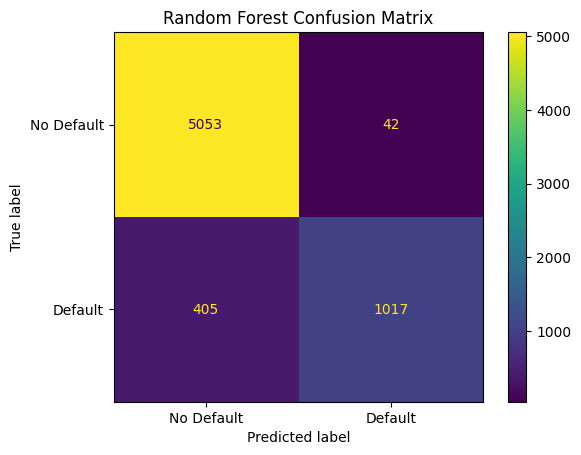

In [ ]:
cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Default", "Default"]
)

disp.plot()

plt.title("Random Forest Confusion Matrix")
plt.show()

<Figure size 800x600 with 0 Axes>

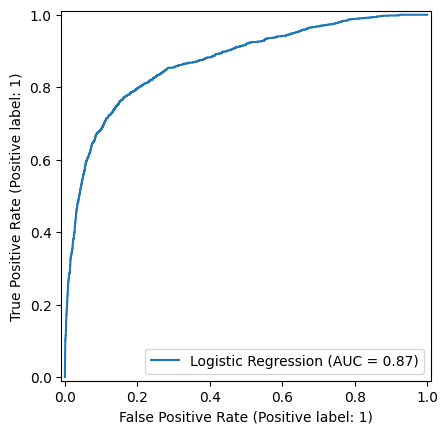

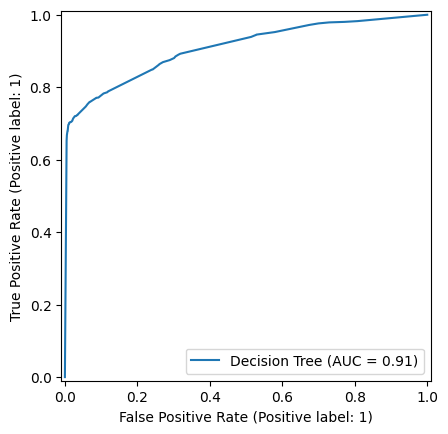

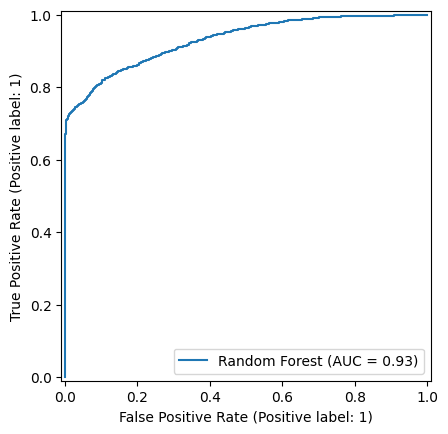

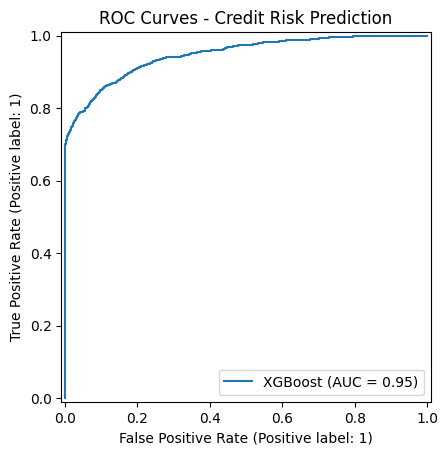

In [ ]:
plt.figure(figsize=(8,6))

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_lr,
    name="Logistic Regression"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_dt,
    name="Decision Tree"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_rf,
    name="Random Forest"
)

RocCurveDisplay.from_predictions(
    y_test,
    y_prob_xgb,
    name="XGBoost"
)

plt.title("ROC Curves - Credit Risk Prediction")
plt.show()

In [ ]:
rf_preprocessor = random_forest_model.named_steps["preprocessor"]
rf_classifier = random_forest_model.named_steps["classifier"]

feature_names = rf_preprocessor.get_feature_names_out()

importance = rf_classifier.feature_importances_

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
5,num__loan_percent_income,0.221735
1,num__person_income,0.157691
4,num__loan_int_rate,0.124780
20,cat__loan_grade_D,0.067758
3,num__loan_amnt,0.065421
10,cat__person_home_ownership_RENT,0.047804
2,num__person_emp_length,0.038769
0,num__person_age,0.031170
17,cat__loan_grade_A,0.029282
7,cat__person_home_ownership_MORTGAGE,0.025039


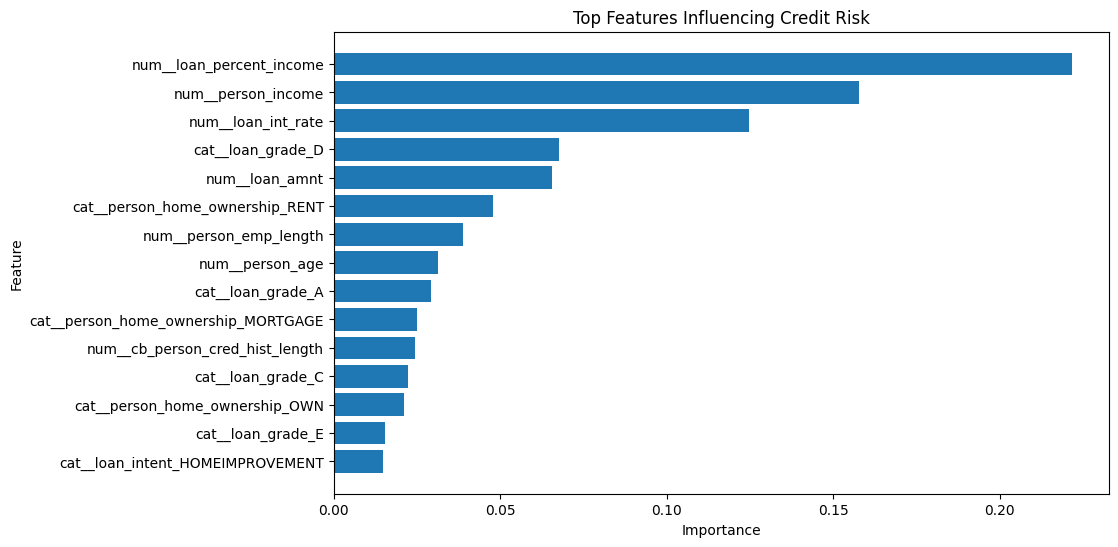

In [ ]:
top_features = feature_importance.head(15)

plt.figure(figsize=(10,6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Top Features Influencing Credit Risk")

plt.gca().invert_yaxis()

plt.show()

In [ ]:
best_model_name = results_df.iloc[0]["Model"]

print("Best Model:", best_model_name)

Best Model: XGBoost


In [ ]:
best_model = random_forest_model

print("Random Forest selected as the final model.")

Random Forest selected as the final model.


In [ ]:
print("Required input columns:")

for column in X.columns:
    print("-", column)

Required input columns:
- person_age
- person_income
- person_home_ownership
- person_emp_length
- loan_intent
- loan_grade
- loan_amnt
- loan_int_rate
- loan_percent_income
- cb_person_default_on_file
- cb_person_cred_hist_length


In [ ]:
# ==========================================
# SAFE NEW APPLICANT PREDICTION
# ==========================================

applicant_data = {
    "person_age": 25,
    "person_income": 60000,
    "person_home_ownership": "RENT",
    "person_emp_length": 3,
    "loan_intent": "EDUCATION",
    "loan_grade": "B",
    "loan_amnt": 10000,
    "loan_int_rate": 11.5,
    "loan_percent_income": 0.17,
    "cb_person_default_on_file": "N",
    "cb_preson_cred_hist_length": 5
}

# Keep only columns that were used during training
new_applicant = pd.DataFrame([applicant_data])

# Match training column order
new_applicant = new_applicant.reindex(columns=X.columns)

# Predict
prediction = best_model.predict(new_applicant)[0]
probability = best_model.predict_proba(new_applicant)[0, 1]

# Result
if probability < 0.30:
    risk_level = "LOW RISK"
    recommendation = "APPROVE"
elif probability < 0.60:
    risk_level = "MEDIUM RISK"
    recommendation = "MANUAL REVIEW"
else:
    risk_level = "HIGH RISK"
    recommendation = "REJECT / MANUAL REVIEW"

print("\n========================================")
print("       CREDIT RISK PREDICTION")
print("========================================")
print(f"Default Probability : {probability * 100:.2f}%")
print(f"Risk Level          : {risk_level}")
print(f"Recommendation      : {recommendation}")
print("========================================")


       CREDIT RISK PREDICTION
Default Probability : 13.80%
Risk Level          : LOW RISK
Recommendation      : APPROVE
